<div style="background-color:black; color:white; padding:40px; text-align:left;">

<span style="font-size:32px; font-weight:bold;">
Práctica GL09 - Regresión Lineal en dos Caminos
</span>  

Nombre: Emily Junny Leniz Coa  
Materia: INF672 - Machine Learning <br>
Fecha: 09/09/2026  

</div>

**Configuración inicial**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

INDIGO, PURPURA, CORAL, TINTA = '#4F46E5', '#7E22CE', '#F43F5E', '#111827'
plt.rcParams.update({
    'figure.figsize': (7, 4.2),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False
})

**Generación de datos simulados
Python**

In [2]:
rng = np.random.default_rng(42)
m = 60

horas = rng.uniform(0, 10, m)
nota = 30 + 5 * horas + rng.normal(0, 5, m)

print('Primeras 5 muestras:')
for h, n in zip(horas[:5], nota[:5]):
    print(f'  horas = {h:5.2f}  nota = {n:6.2f}')

Primeras 5 muestras:
  horas =  7.74  nota =  64.37
  horas =  4.39  nota =  56.79
  horas =  8.59  nota =  64.52
  horas =  6.97  nota =  63.19
  horas =  0.94  nota =  35.52


**Gráfico de dispersión inicial**

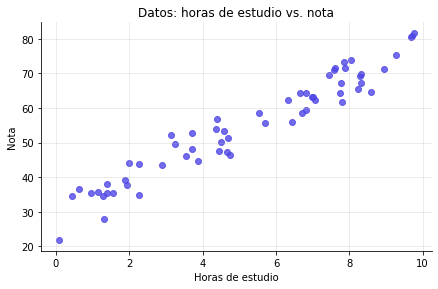

In [3]:
plt.scatter(horas, nota, color=INDIGO, alpha=0.8)
plt.xlabel('Horas de estudio')
plt.ylabel('Nota')
plt.title('Datos: horas de estudio vs. nota')
plt.show()

**PARTE A - División de datos (Train/Test)**

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X = horas.reshape(-1, 1)
y = nota

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print('Entrenamiento:', X_train.shape, 'Prueba:', X_test.shape)

Entrenamiento: (48, 1) Prueba: (12, 1)


**Entrenamiento del modelo**

In [29]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

w_sk = modelo.coef_[0]
b_sk = modelo.intercept_

print("Pendiente w =", round(w_sk, 4))
print("Intercepto b =", round(b_sk, 4))
print("Modelo aprendido: nota =", round(b_sk, 2), "+", round(w_sk, 2), "horas")

Pendiente w = 5.0675
Intercepto b = 28.5394
Modelo aprendido: nota = 28.54 + 5.07 horas


**Evaluación y métricas**

In [20]:
y_pred = modelo.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("MAE (error absoluto medio)    =", round(mae, 3), "puntos")
print("MSE (error cuadratico medio)  =", round(mse, 3))
print("RMSE (raiz del MSE)           =", round(np.sqrt(mse), 3), "puntos")
print("R2 (coef. de determinacion)   =", round(r2_score(y_test, y_pred), 3))

MAE (error absoluto medio)    = 2.781 puntos
MSE (error cuadratico medio)  = 12.188
RMSE (raiz del MSE)           = 3.491 puntos
R2 (coef. de determinacion)   = 0.946


**Predicción para casos nuevos**

In [7]:
nuevos = np.array([[2], [5], [8]])

for h, p in zip(nuevos.ravel(), modelo.predict(nuevos)):
    print("Con", h, "horas de estudio se predice una nota de", round(p, 1))

Con 2 horas de estudio se predice una nota de 38.7
Con 5 horas de estudio se predice una nota de 53.9
Con 8 horas de estudio se predice una nota de 69.1


**Gráfico de la recta de regresión (scikit-learn)**

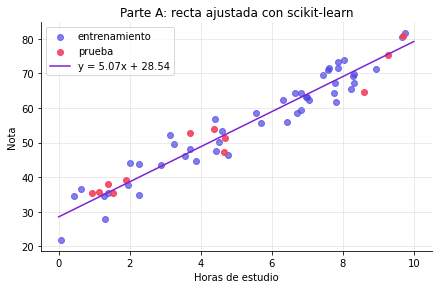

In [21]:
xs = np.linspace(0, 10, 100).reshape(-1, 1)

etiqueta_recta = "y = " + str(round(w_sk, 2)) + "x + " + str(round(b_sk, 2))

plt.scatter(X_train, y_train, color=INDIGO, alpha=0.7, label='entrenamiento')
plt.scatter(X_test, y_test, color=CORAL, alpha=0.9, label='prueba')
plt.plot(xs, modelo.predict(xs), color=PURPURA, label=etiqueta_recta)
plt.xlabel('Horas de estudio')
plt.ylabel('Nota')
plt.title('Parte A: recta ajustada con scikit-learn')
plt.legend()
plt.show()

**PARTE B - Función de costo**

In [22]:
def costo(w, b, x, y):
    y_pred = w * x + b
    return np.mean((y_pred - y) ** 2) / 2

x_train, x_test = X_train.ravel(), X_test.ravel()

c0 = round(costo(0, 0, x_train, y_train), 2)
c_real = round(costo(5, 30, x_train, y_train), 2)

print("J(0,  0) =", c0, "<- recta en 0")
print("J(5, 30) =  ", c_real, "<- relacion real")

J(0,  0) = 1667.25 <- recta en 0
J(5, 30) =   7.88 <- relacion real


**Gradientes**

In [23]:
def gradientes(w, b, x, y):
    error = (w * x + b) - y
    dw = np.mean(error * x)
    db = np.mean(error)
    return dw, db

dw, db = gradientes(0, 0, x_train, y_train)

print("En (w, b) = (0, 0): dJ/dw =", round(dw, 2), ", dJ/db =", round(db, 2))

En (w, b) = (0, 0): dJ/dw = -339.86 , dJ/db = -55.98


**Algoritmo de descenso de gradiente**

In [24]:
def descenso_gradiente(x, y, alpha=0.01, iteraciones=10_000):
    w, b = 0.0, 0.0
    historial = []
    for i in range(iteraciones):
        dw, db = gradientes(w, b, x, y)
        w = w - alpha * dw
        b = b - alpha * db
        historial.append(costo(w, b, x, y))
        if i in (0, 10, 100, 1000, iteraciones - 1):
            print("iter", str(i).rjust(5), ": w =", round(w, 4), " b =", round(b, 4), " J =", round(historial[-1], 4))
    return w, b, historial

w_gd, b_gd, historial = descenso_gradiente(x_train, y_train, alpha=0.01, iteraciones=10_000)

iter     0 : w = 3.3986  b = 0.5598  J = 702.4903
iter    10 : w = 8.9765  b = 1.9226  J = 77.3678
iter   100 : w = 8.3954  b = 6.1889  J = 56.6861
iter  1000 : w = 5.6493  b = 24.632  J = 8.7716
iter  9999 : w = 5.0675  b = 28.5394  J = 7.261


**Curva de aprendizaje**

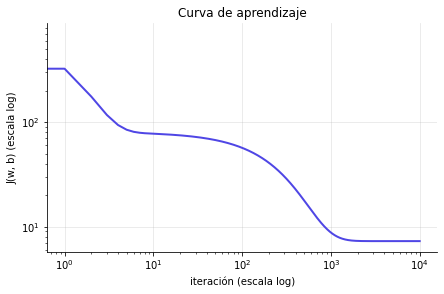

In [12]:
plt.plot(historial, color=INDIGO, lw=2)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('iteración (escala log)')
plt.ylabel('J(w, b) (escala log)')
plt.title('Curva de aprendizaje')
plt.show()

**Evaluación del modelo propio**

In [25]:
y_pred_gd = w_gd * x_test + b_gd

mae = np.mean(np.abs(y_test - y_pred_gd))
rmse = np.sqrt(np.mean((y_test - y_pred_gd) ** 2))
r2 = 1 - (np.sum((y_test - y_pred_gd) ** 2) / np.sum((y_test - y_test.mean()) ** 2))

print("MAE  =", round(mae, 3), "puntos")
print("RMSE =", round(rmse, 3), "puntos")
print("R2   =", round(r2, 3))

MAE  = 2.781 puntos
RMSE = 3.491 puntos
R2   = 0.946


**Comparación cuantitativa de ambos métodos**

In [28]:
import pandas as pd

tabla_comparacion = pd.DataFrame({
    'w': [5.0000, w_sk, w_gd],
    'b': [30.0000, b_sk, b_gd]
}, index=['Valor real', 'scikit-learn', 'Descenso de gradiente'])

display(tabla_comparacion)

print("Diferencia |w_sk - w_gd| =", round(abs(w_sk - w_gd), 10))
print("Diferencia |b_sk - b_gd| =", round(abs(b_sk - b_gd), 10))

,w,b
Valor real,5.00000,30.000000
scikit-learn,5.06745,28.539418
Descenso de gradiente,5.06745,28.539418


Diferencia |w_sk - w_gd| = 1.55e-08
Diferencia |b_sk - b_gd| = 1.044e-07


**Comparación gráfica final**

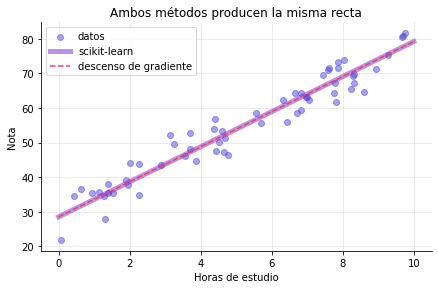

In [15]:
plt.scatter(horas, nota, color=INDIGO, alpha=0.5, label='datos')
plt.plot(xs, modelo.predict(xs), color=PURPURA, lw=5, alpha=0.5, label='scikit-learn')
plt.plot(xs, w_gd * xs + b_gd, color=CORAL, lw=1.5, ls='--', label='descenso de gradiente')
plt.xlabel('Horas de estudio')
plt.ylabel('Nota')
plt.title('Ambos métodos producen la misma recta')
plt.legend()
plt.show()